In [5]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ta.momentum import RSIIndicator
from ta.trend import MACD
from datetime import datetime, timedelta

# Grafiklerin daha güzel görünmesi için ayar
plt.style.use('seaborn-v0_8')
%matplotlib inline

In [6]:
sembol = "THYAO.IS"
bitis_tarihi = datetime.now()
baslangic_tarihi = bitis_tarihi - timedelta(days=3*365)

print(f"{sembol} verileri indiriliyor...")
df = yf.download(sembol, start=baslangic_tarihi, end=bitis_tarihi)

# yfinance bazen MultiIndex kolon döndürebilir, bunu düzeltiyoruz
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Eksik veri kontrolü
print("\nEksik Veri Sayısı:")
print(df.isnull().sum())

# Varsa eksik verileri temizle
df.dropna(inplace=True)

THYAO.IS verileri indiriliyor...


[*********************100%***********************]  1 of 1 completed


Eksik Veri Sayısı:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [7]:
# RSI (14) Hesaplama
rsi_ozelligi = RSIIndicator(close=df['Close'], window=14)
df['RSI'] = rsi_ozelligi.rsi()

# MACD Hesaplama
macd_ozelligi = MACD(close=df['Close'])
df['MACD'] = macd_ozelligi.macd()
df['MACD_Sinyal'] = macd_ozelligi.macd_signal()

# İndikatör hesaplamalarından kaynaklı (ilk 14-26 gün) oluşan NaN değerleri temizle
df.dropna(inplace=True)

print("İndikatörler başarıyla eklendi.")

İndikatörler başarıyla eklendi.


Veri Seti Son Hali:


Price,Close,High,Low,Open,Volume,RSI,MACD,MACD_Sinyal
Date,,,,,,,,
2023-12-04,255.943665,257.897433,252.524570,255.455222,40460792,67.330529,9.439586,10.241403
2023-12-05,253.012985,257.164743,250.814996,256.432080,32211363,63.451650,9.034487,10.000020
2023-12-06,245.442154,253.745670,245.197933,253.013006,28987606,54.686935,8.010204,9.602057
2023-12-07,253.745667,253.745667,243.146467,246.419035,34974072,61.042937,7.778807,9.237407
2023-12-08,248.128586,254.966775,246.907481,253.257228,28379738,55.383485,7.060779,8.802081


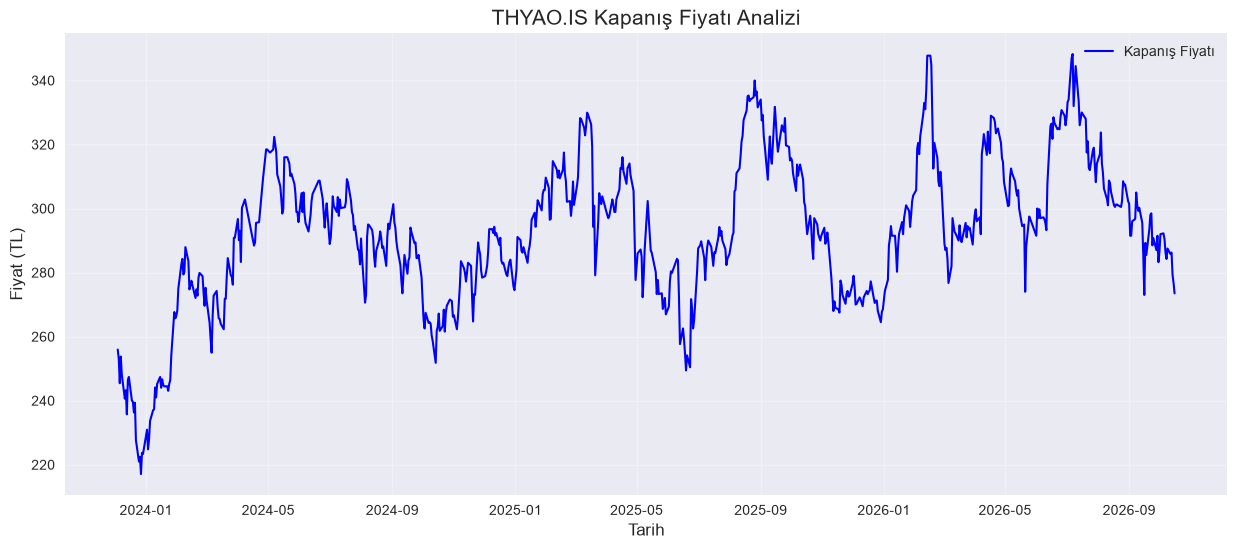

In [8]:
# İlk 5 satırı göster
print("Veri Seti Son Hali:")
display(df.head())

# Kapanış Fiyatı Grafiği
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Close'], color='blue', linewidth=1.5, label='Kapanış Fiyatı')
plt.title(f'{sembol} Kapanış Fiyatı Analizi', fontsize=15)
plt.xlabel('Tarih', fontsize=12)
plt.ylabel('Fiyat (TL)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# Bir sonraki günün kapanış fiyatını yan sütuna alıyoruz
df['Next_Day_Close'] = df['Close'].shift(-1)

# Yarının fiyatı bugünden büyükse 1, değilse 0 (Hedef Sınıflandırma)
df['Target'] = (df['Next_Day_Close'] > df['Close']).astype(int)

# shift(-1) işleminden dolayı son satırda yarının verisi olmayacağı için NaN oluşur. 
# Bu satırı eğitimde kullanamayacağımız için siliyoruz.
df.dropna(inplace=True)

# İstenen sütunları ve ilk 5 satırı yazdır
secili_sutunlar = ['Close', 'RSI', 'MACD', 'Target']
print("Model İçin Hazırlanan Veri Seti (İlk 5 Satır):")
display(df[secili_sutunlar].head())

# Hedef değişkenin dağılımına hızlıca bir bakalım (Dengesiz veri kontrolü)
print("\nHedef Değişken Dağılımı:")
print(df['Target'].value_counts())

Model İçin Hazırlanan Veri Seti (İlk 5 Satır):


Price,Close,RSI,MACD,Target
Date,,,,
2023-12-04,255.943665,67.330529,9.439586,0
2023-12-05,253.012985,63.451650,9.034487,0
2023-12-06,245.442154,54.686935,8.010204,1
2023-12-07,253.745667,61.042937,7.778807,0
2023-12-08,248.128586,55.383485,7.060779,0



Hedef Değişken Dağılımı:
Target
0    378
1    339
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Özellikleri (X) ve Hedefi (y) Belirleme
# Sadece indikatörleri ipucu olarak veriyoruz, Target ise tahmin edilecek değer
X = df[['RSI', 'MACD']]
y = df['Target']

# 2. Veriyi %80 Eğitim, %20 Test olarak ayırma
# Zaman serisi olduğu için shuffle=False yaparak geçmişten geleceğe sırayı koruyoruz
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=False)

# 3. XGBoost Modelini Oluşturma ve Eğitme
# random_state=42: Sonuçların her çalıştırdığında aynı çıkması için
# use_label_encoder=False ve eval_metric='logloss': Güncel XGBoost uyarılarını engellemek için
model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

# 4. Test Verisi Üzerinde Tahmin Yapma
y_pred = model.predict(X_test)

# 5. Başarı Oranını Hesaplama ve Yazdırma
dogruluk_skoru = accuracy_score(y_test, y_pred)
print(f"--- XGBoost Model Sonuçları ---")
print(f"Test Seti Doğruluk Skoru: %{dogruluk_skoru * 100:.2f}")

# Ekstra: Sınıflandırma detaylarını görme (Hangi sınıfta daha başarılı?)
print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

--- XGBoost Model Sonuçları ---
Test Seti Doğruluk Skoru: %44.44

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.50      0.44      0.47        80
           1       0.39      0.45      0.42        64

    accuracy                           0.44       144
   macro avg       0.45      0.45      0.44       144
weighted avg       0.45      0.44      0.45       144



c:\Users\ADEM\Desktop\borsa_projesi\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:36:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


c:\Users\ADEM\Desktop\borsa_projesi\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:38:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


--- Genişletilmiş Özelliklerle XGBoost Sonuçları ---
Kullanılan Özellik Sayısı: 10
Yeni Test Seti Doğruluk Skoru: %52.24


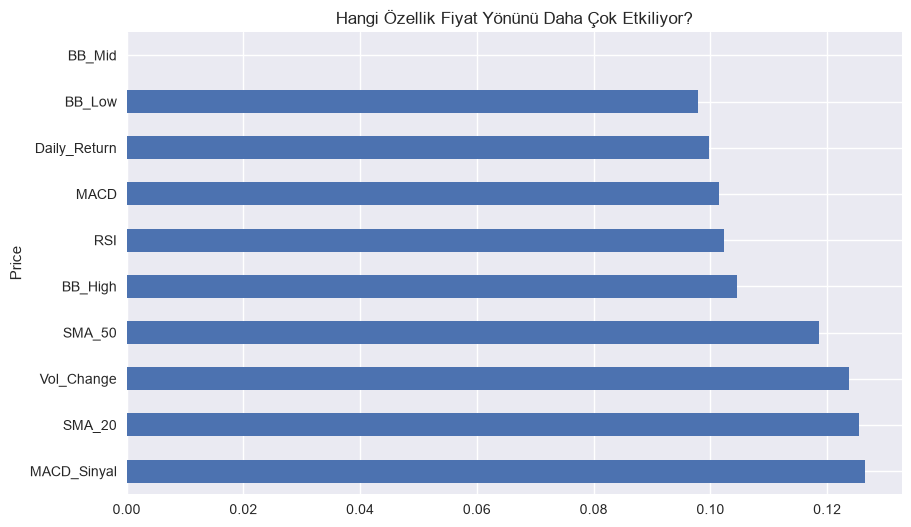

In [11]:
from ta.volatility import BollingerBands
from ta.trend import SMAIndicator

# 1. Yeni Teknik İndikatörlerin Eklenmesi
# SMA 20 ve 50
df['SMA_20'] = SMAIndicator(close=df['Close'], window=20).sma_indicator()
df['SMA_50'] = SMAIndicator(close=df['Close'], window=50).sma_indicator()

# Bollinger Bantları
bb = BollingerBands(close=df['Close'], window=20, window_dev=2)
df['BB_High'] = bb.bollinger_hband()
df['BB_Mid'] = bb.bollinger_mavg()
df['BB_Low'] = bb.bollinger_lband()

# Hacim Değişimi ve Günlük Getiri
df['Vol_Change'] = df['Volume'].pct_change()
df['Daily_Return'] = df['Close'].pct_change()

# 2. Yeni indikatörler ve pct_change nedeniyle oluşan NaN değerleri temizle
df.dropna(inplace=True)

# 3. İpucu (X) Değişkenini Genişletme
# Modelin ufkunu genişletmek için tüm bu yeni bilgileri modele veriyoruz
yeni_ozellikler = [
    'RSI', 'MACD', 'MACD_Sinyal', 
    'SMA_20', 'SMA_50', 
    'BB_High', 'BB_Mid', 'BB_Low', 
    'Vol_Change', 'Daily_Return'
]

X = df[yeni_ozellikler]
y = df['Target']

# 4. Veriyi Yeniden Bölme (Zaman sırasını koruyarak)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, shuffle=False)

# 5. Modeli Yeniden Eğitme
model_v2 = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
model_v2.fit(X_train, y_train)

# 6. Yeni Sonuçları Hesaplama
y_pred_v2 = model_v2.predict(X_test)
yeni_dogruluk = accuracy_score(y_test, y_pred_v2)

print(f"--- Genişletilmiş Özelliklerle XGBoost Sonuçları ---")
print(f"Kullanılan Özellik Sayısı: {len(yeni_ozellikler)}")
print(f"Yeni Test Seti Doğruluk Skoru: %{yeni_dogruluk * 100:.2f}")

# Hangi özelliğin daha önemli olduğunu görelim (Feature Importance)
plt.figure(figsize=(10, 6))
feat_importances = pd.Series(model_v2.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh')
plt.title('Hangi Özellik Fiyat Yönünü Daha Çok Etkiliyor?')
plt.show()

In [13]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from xgboost import XGBClassifier
from scipy.stats import uniform, randint, loguniform

# 1. Zaman Serisine Uygun Cross-Validation (Çapraz Doğrulama) Stratejisi
# Veriyi kronolojik olarak 5 farklı parçaya bölerek test eder
tscv = TimeSeriesSplit(n_splits=5,gap=10)

# 2. XGBoost İçin Parametre Aralığı (Param Grid)
param_dist = {
    'max_depth': randint(3, 8),
    'learning_rate': loguniform(0.01, 0.2),
    'n_estimators': randint(200, 800),
    'subsample': uniform(0.6, 0.4),         # 0.6 - 1.0
    'colsample_bytree': uniform(0.6, 0.4),
    'min_child_weight': randint(1, 5),
    'gamma': uniform(0, 0.3),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-1, 10),
}

# 3. RandomizedSearchCV Modeli
# n_iter=20: 20 farklı rastgele kombinasyon dene
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss',scale_pos_weight=1.1)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=50,
    cv=tscv,
    scoring='accuracy',
    verbose=1,
    random_state=42,
    n_jobs=-1,
)

# 4. Eğitim (Sadece Train Seti ile)
print("Optimizasyon başlatılıyor (Bu işlem biraz zaman alabilir)...")
random_search.fit(X_train, y_train)

# 5. En İyi Parametreler ve Yeni Tahmin
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
optimum_dogruluk = accuracy_score(y_test, y_pred_tuned)

print("\n--- Optimizasyon Sonuçları ---")
print(f"En İyi Parametreler: {random_search.best_params_}")
print(f"Optimize Edilmiş Test Skoru: %{optimum_dogruluk * 100:.2f}")

# Detaylı rapor
print("\nFinal Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred_tuned))

Optimizasyon başlatılıyor (Bu işlem biraz zaman alabilir)...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

--- Optimizasyon Sonuçları ---
En İyi Parametreler: {'colsample_bytree': np.float64(0.8721230154351118), 'gamma': np.float64(0.1351497755908629), 'learning_rate': np.float64(0.010405384007798954), 'max_depth': 3, 'min_child_weight': 4, 'n_estimators': 213, 'reg_alpha': np.float64(1.7123375973163988), 'reg_lambda': np.float64(0.4066563313514795), 'subsample': np.float64(0.6390688456025535)}
Optimize Edilmiş Test Skoru: %52.99

Final Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.56      0.80      0.66        76
           1       0.40      0.17      0.24        58

    accuracy                           0.53       134
   macro avg       0.48      0.49      0.45       134
weighted avg       0.49      0.53      0.48       134

